In [1]:
import os
import re
import json
import glob
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import rankdata

INPUT = "/kaggle/input/datasets/nocturnalnerd18"
OUT_DIR = "/kaggle/working"
SOURCES = {"llava": "patch-llava-intervene", "qwen": "patch-qwen-intervene"}
HELD = ["val", "test"]
N_BOOT = 1000
MIN_N = 10
rng = np.random.default_rng(1)


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


DATA = {}
for model_, slug in SOURCES.items():
    src = f"{INPUT}/{slug}"
    if not os.path.exists(f"{src}/circuit_meta.json"):
        print(f"{model_}: {slug} not attached, skipped")
        continue
    with open(f"{src}/circuit_meta.json") as f:
        cm = json.load(f)
    entries = []
    for path in sorted(glob.glob(f"{src}/B_batch_*.pt"), key=batch_number):
        entries.extend(torch.load(path))
    good = [e for e in entries if e["ok"] and bool(torch.isfinite(e["margins"]).all())]
    DATA[model_] = {
        "names": cm["intervention_names"],
        "M": np.stack([e["margins"].numpy() for e in good]).astype(np.float64),
        "grp": np.array([e["group"] for e in good]),
        "split": np.array([e["split"] for e in good]),
    }
    d = DATA[model_]
    assert d["names"][0] == "base"
    print(f"{model_}: {len(entries)} entries, {len(good)} ok and finite, {len(d['names'])} interventions")
    print(pd.crosstab(d["grp"], d["split"]).to_string())

llava: 480 entries, 480 ok and finite, 11 interventions
col_0      test  val
row_0               
fy_driven    58   62
fy_prior     63   57
true_no      57   63
true_yes     57   63
qwen: patch-qwen-intervene not attached, skipped


In [2]:
def auc_cols(Ma, Mb):
    na, nb = len(Ma), len(Mb)
    r = rankdata(np.vstack([Ma, Mb]), axis=0)
    return (r[na:].sum(0) - nb * (nb + 1) / 2) / (na * nb)


def op_cols(Ma, Mb):
    K = Ma.shape[1]
    fixed = (Ma < 0).mean(0)
    loss = (Mb < 0).mean(0)
    excess = np.full(K, np.nan)
    for k in range(K):
        if 0.05 <= fixed[k] <= 0.95:
            s = np.quantile(Ma[:, 0], fixed[k])
            excess[k] = (Mb[:, 0] < s).mean() - loss[k]
    return fixed, loss, excess


def stats(Ma, Mb):
    auc = auc_cols(Ma, Mb)
    fixed, loss, excess = op_cols(Ma, Mb)
    shift_a = (Ma - Ma[:, [0]]).mean(0)
    shift_b = (Mb - Mb[:, [0]]).mean(0)
    return {"auc": auc, "dauc": auc - auc[0], "fixed": fixed, "loss": loss, "excess": excess, "dshift": shift_b - shift_a}


def boot(Ma, Mb):
    point = stats(Ma, Mb)
    draws = {k: [] for k in point}
    for _ in range(N_BOOT):
        s = stats(Ma[rng.integers(0, len(Ma), len(Ma))], Mb[rng.integers(0, len(Mb), len(Mb))])
        for k in point:
            draws[k].append(s[k])
    ci = {k: (np.nanpercentile(np.stack(v), 2.5, axis=0), np.nanpercentile(np.stack(v), 97.5, axis=0)) for k, v in draws.items()}
    return point, ci


def cell(point, ci, key, k, d=3, plus=True):
    p = f"{point[key][k]:+.{d}f}" if plus else f"{point[key][k]:.{d}f}"
    if np.isnan(point[key][k]):
        return "n/a"
    lo, hi = ci[key][0][k], ci[key][1][k]
    return f"{p} [{lo:+.{d}f}, {hi:+.{d}f}]" if plus else f"{p} [{lo:.{d}f}, {hi:.{d}f}]"


RESULTS = {}
for model_, d in DATA.items():
    M, grp, split = d["M"], d["grp"], d["split"]
    for a_name in ["fy_driven", "fy_prior"]:
        for subset in ["all", "held-out"]:
            keep = np.ones(len(grp), dtype=bool) if subset == "all" else np.isin(split, HELD)
            Ma, Mb = M[(grp == a_name) & keep], M[(grp == "true_yes") & keep]
            if len(Ma) < MIN_N or len(Mb) < MIN_N:
                print(f"{model_} {a_name} vs true_yes ({subset}): {len(Ma)} and {len(Mb)} questions, skipped")
                continue
            point, ci = boot(Ma, Mb)
            RESULTS[(model_, a_name, subset)] = (point, ci, len(Ma), len(Mb))
            tab = pd.DataFrame({
                "AUC": [cell(point, ci, "auc", k, 3, False) for k in range(len(d["names"]))],
                "AUC change": [cell(point, ci, "dauc", k) for k in range(len(d["names"]))],
                "fixed": [f"{point['fixed'][k]:.2f}" for k in range(len(d["names"]))],
                "true_yes lost": [f"{point['loss'][k]:.2f}" for k in range(len(d["names"]))],
                "edge over bias shift": [cell(point, ci, "excess", k, 2) for k in range(len(d["names"]))],
                "selective shift": [cell(point, ci, "dshift", k, 2) for k in range(len(d["names"]))],
            }, index=d["names"])
            print(f"--- {model_}: {a_name} (n={len(Ma)}) against true_yes (n={len(Mb)}), {subset} ---")
            print(tab.to_string())
print("AUC is the chance that a true_yes question has a higher Yes margin than the hallucinated one; a constant shift or a rescaling of the margins cannot change it, so a rise in AUC means the intervention reorders the questions")
print("edge over bias shift: true_yes questions a plain constant shift of the baseline margins would lose to fix the same share of hallucinations, minus the share the intervention loses; positive means the intervention beats a threshold move")
print("selective shift: mean change of the margin on true_yes minus on the hallucinated group, logits; positive means the hallucinated group is pushed further toward No")

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


--- llava: fy_driven (n=120) against true_yes (n=120), all ---
                                     AUC               AUC change fixed true_yes lost  edge over bias shift       selective shift
base                0.485 [0.415, 0.555]  +0.000 [+0.000, +0.000]  0.00          0.00                   n/a  +0.00 [+0.00, +0.00]
abl L17             0.506 [0.434, 0.575]  +0.022 [+0.009, +0.034]  0.03          0.04                   n/a  +0.11 [+0.02, +0.19]
abl L16+L17         0.555 [0.479, 0.624]  +0.070 [+0.044, +0.096]  0.14          0.21  +0.08 [-0.02, +0.15]  +0.28 [+0.13, +0.44]
abl M2              0.592 [0.520, 0.657]  +0.107 [+0.070, +0.140]  0.34          0.28  +0.07 [+0.02, +0.19]  +0.40 [+0.23, +0.58]
x0.5 M2             0.526 [0.453, 0.595]  +0.041 [+0.025, +0.056]  0.02          0.06                   n/a  +0.21 [+0.12, +0.29]
L28 x2              0.518 [0.444, 0.593]  +0.033 [+0.016, +0.052]  0.49          0.44  +0.04 [+0.00, +0.11]  +0.12 [+0.05, +0.20]
L28 x3              0.583 [

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


--- llava: fy_driven (n=120) against true_yes (n=120), held-out ---
                                     AUC               AUC change fixed true_yes lost  edge over bias shift       selective shift
base                0.485 [0.412, 0.558]  +0.000 [+0.000, +0.000]  0.00          0.00                   n/a  +0.00 [+0.00, +0.00]
abl L17             0.506 [0.431, 0.581]  +0.022 [+0.009, +0.033]  0.03          0.04                   n/a  +0.11 [+0.02, +0.19]
abl L16+L17         0.555 [0.478, 0.629]  +0.070 [+0.045, +0.095]  0.14          0.21  +0.08 [-0.02, +0.15]  +0.28 [+0.13, +0.43]
abl M2              0.592 [0.514, 0.664]  +0.107 [+0.073, +0.141]  0.34          0.28  +0.07 [+0.01, +0.18]  +0.40 [+0.23, +0.59]
x0.5 M2             0.526 [0.453, 0.599]  +0.041 [+0.026, +0.057]  0.02          0.06                   n/a  +0.21 [+0.12, +0.30]
L28 x2              0.518 [0.440, 0.593]  +0.033 [+0.015, +0.054]  0.49          0.44  +0.04 [+0.00, +0.11]  +0.12 [+0.04, +0.20]
L28 x3              0.

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


--- llava: fy_prior (n=120) against true_yes (n=120), all ---
                                     AUC               AUC change fixed true_yes lost  edge over bias shift       selective shift
base                0.901 [0.861, 0.936]  +0.000 [+0.000, +0.000]  0.00          0.00                   n/a  +0.00 [+0.00, +0.00]
abl L17             0.915 [0.879, 0.947]  +0.014 [+0.002, +0.027]  0.62          0.04  +0.05 [+0.02, +0.12]  -0.27 [-0.35, -0.20]
abl L16+L17         0.906 [0.867, 0.940]  +0.005 [-0.015, +0.026]  0.82          0.21  -0.03 [-0.07, +0.02]  -0.37 [-0.50, -0.25]
abl M2              0.906 [0.866, 0.940]  +0.005 [-0.021, +0.032]  0.91          0.28  -0.03 [-0.12, +0.05]  -0.38 [-0.53, -0.24]
x0.5 M2             0.914 [0.878, 0.946]  +0.013 [-0.001, +0.029]  0.58          0.06  +0.02 [-0.02, +0.07]  -0.14 [-0.21, -0.06]
L28 x2              0.894 [0.849, 0.932]  -0.007 [-0.025, +0.012]  0.98          0.44                   n/a  -0.22 [-0.29, -0.14]
L28 x3              0.833 [0

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


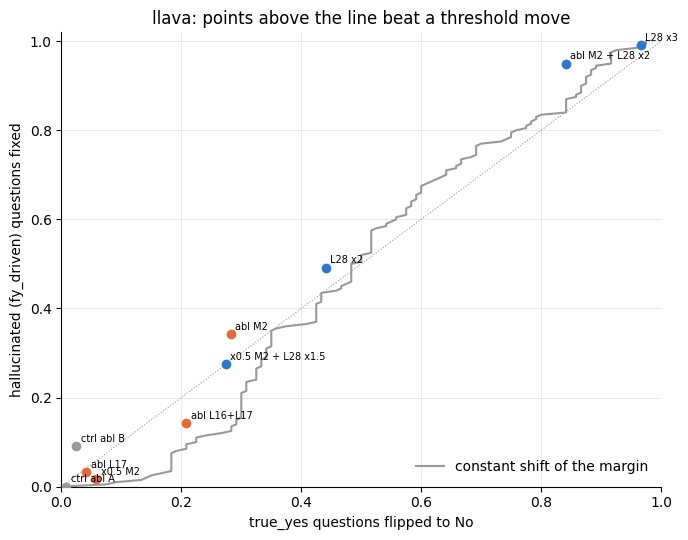

In [3]:
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#999999"
fig, axes = plt.subplots(1, len(DATA), figsize=(7 * len(DATA), 5.5), squeeze=False)
for ax, (model_, d) in zip(axes[0], DATA.items()):
    M, grp = d["M"], d["grp"]
    Ma, Mb = M[grp == "fy_driven"], M[grp == "true_yes"]
    qs = np.linspace(0, 1, 201)
    ref = [(Mb[:, 0] < np.quantile(Ma[:, 0], q)).mean() if q > 0 else 0.0 for q in qs]
    ax.plot(ref, qs, color=GREY, lw=1.5, label="constant shift of the margin")
    ax.plot([0, 1], [0, 1], color=GREY, lw=0.8, ls=":")
    fixed, loss, _ = op_cols(Ma, Mb)
    for k, n in enumerate(d["names"]):
        if n == "base":
            continue
        color = GREY if n.startswith("ctrl") else BLUE if any(t in n for t in ("x2", "x3", "x1.5")) else ORANGE
        ax.scatter(loss[k], fixed[k], s=36, color=color, zorder=3)
        ax.annotate(n, (loss[k], fixed[k]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("true_yes questions flipped to No")
    ax.set_ylabel("hallucinated (fy_driven) questions fixed")
    ax.set_title(f"{model_}: points above the line beat a threshold move")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(color="#e5e5e2", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/intervention_selectivity.png", dpi=150)
plt.show()

summary = {}
for (model_, a_name, subset), (point, ci, na, nb) in RESULTS.items():
    summary[f"{model_}/{a_name}/{subset}"] = {
        "names": DATA[model_]["names"], "n_a": na, "n_b": nb,
        **{k: [None if np.isnan(x) else float(x) for x in v] for k, v in point.items()},
        **{f"{k}_lo": [None if np.isnan(x) else float(x) for x in ci[k][0]] for k in ci},
        **{f"{k}_hi": [None if np.isnan(x) else float(x) for x in ci[k][1]] for k in ci},
    }
with open(f"{OUT_DIR}/intervention_selectivity.json", "w") as f:
    json.dump(summary, f)